In [1]:
#%pip install torchvision

In [2]:
import torch
import os
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image

In [3]:
# images load => transform => dataset of all imgs
class ImageProcessor:
    def __init__(self, root_dir_path, transformations=None):
        self.root_dir_path = root_dir_path
        self.transformations = transformations

        # Only load image files; folders and metadata files are not images.
        valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        self.all_img_paths = [
            os.path.join(root_dir_path, img)
            for img in os.listdir(root_dir_path)
            if os.path.isfile(os.path.join(root_dir_path, img))
            and os.path.splitext(img)[1].lower() in valid_extensions
        ]

    def __len__(self):
        return len(self.all_img_paths)

    def __getitem__(self, idx):
        img_path = self.all_img_paths[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transformations:
            img = self.transformations(img)

        return img

In [4]:
root_dir_path = "./img_align_celeba"

transformations = transforms.Compose([
    transforms.CenterCrop(178),  # 178x218 => 178x178
    transforms.Resize(64), # 64x64
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) #[-1,1]
])

In [5]:
dataset = ImageProcessor(root_dir_path, transformations)
print(f"loaded {len(dataset)} images")

loaded 202598 images


In [6]:
dataloader = DataLoader(dataset, batch_size=128, shuffle=True)

### Generator Network

In [7]:
import torch.nn as nn 
import torch.optim as optim
import numpy as np

In [8]:
class Generator(nn.Module):
    def __init__(self, z_dim=100, img_channels=3): 
        super(Generator, self).__init__()

        # fully connected (dense) layers
        self.model = nn.Sequential(
            nn.Linear(z_dim, 256),  # 100 => 256
            nn.ReLU(),

            nn.Linear(256, 512),
            nn.ReLU(),

            nn.Linear(512, 1024),
            nn.ReLU(),

            nn.Linear(1024, img_channels * 64 * 64),
            nn.Tanh()
        )

    def forward(self, z):
        img = self.model(z)
        img = img.view(img.size(0), 3, 64, 64)
        return img

### Discriminator Network

In [9]:
class Discriminator(nn.Module):
    def __init__(self, img_channels=3):
        super(Discriminator, self).__init__()

        self.model = nn.Sequential(
            nn.Flatten(),  # 4D tensor => 1D

            nn.Linear(img_channels *64 *64, 1024), 
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(1024, 512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(256, 1)
        )

    def forward(self, z):
        return self.model(z)

In [10]:
import torch
# device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"device is {device}")

device is cpu


In [11]:
GAN_loss = nn.BCEWithLogitsLoss()

generator = Generator()
g_optimizer = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))

discriminator = Discriminator()
d_optimizer = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

generator = generator.to(device)
discriminator = discriminator.to(device)

### Training the GAN

In [12]:
def train(generator, discriminator, dataloader, checkpoint_path="gan_checkpoint.pth", resume=False):

    start_epoch = 0
    if resume:
        checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
        generator.load_state_dict(checkpoint["generator_state_dict"])
        discriminator.load_state_dict(checkpoint["discriminator_state_dict"])
        g_optimizer.load_state_dict(checkpoint["g_optimizer_state_dict"])
        d_optimizer.load_state_dict(checkpoint["d_optimizer_state_dict"])
        start_epoch = checkpoint["epoch"] + 1
        fixed_noise = checkpoint["fixed_noise"].to(device)
    else:
        fixed_noise = torch.randn(8, 100, device=device)

    epoch = start_epoch
    while True:
        for i, imgs in enumerate(dataloader):
            real_imgs = imgs.to(device)
            batch_size = real_imgs.size(0)

            # creates real imgs labels & fake imgs labels
            real_labels = torch.ones(batch_size, 1).to(device)
            fake_labels = torch.zeros(batch_size, 1).to(device)

            # train the Discriminator
            d_optimizer.zero_grad()

            fake_imgs = generator(torch.randn(batch_size, 100).to(device))

            real_loss = GAN_loss(discriminator(real_imgs), real_labels)
            fake_loss = GAN_loss(discriminator(fake_imgs.detach()), fake_labels)

            d_loss = (real_loss + fake_loss)/2

            d_loss.backward()
            d_optimizer.step()

            # train the Generator
            for param in discriminator.parameters():
                param.requires_grad_(False)

            g_optimizer.zero_grad()

            g_loss = GAN_loss(discriminator(fake_imgs), real_labels)

            g_loss.backward()
            g_optimizer.step()

            for param in discriminator.parameters():
                param.requires_grad_(True)

            if i % 50 == 0:
                print(f"for epoch: {epoch+1}... batch: {i+1}... G-loss: {g_loss}... D-loss: {d_loss}")

        # Save training state after each completed epoch so training can be resumed.
        checkpoint_dir = os.path.dirname(checkpoint_path)
        if checkpoint_dir:
            os.makedirs(checkpoint_dir, exist_ok=True)
        torch.save({
            "epoch": epoch,
            "generator_state_dict": generator.state_dict(),
            "discriminator_state_dict": discriminator.state_dict(),
            "g_optimizer_state_dict": g_optimizer.state_dict(),
            "d_optimizer_state_dict": d_optimizer.state_dict(),
            "fixed_noise": fixed_noise.cpu(),
        }, checkpoint_path)
        save_generated_images(generator, epoch, device, fixed_noise)
        epoch += 1

In [13]:
import matplotlib.pyplot as plt
import torchvision

def save_generated_images(generator, epoch, device, fixed_noise):
    was_training = generator.training
    generator.eval()
    with torch.no_grad():
        generated_imgs = generator(fixed_noise).cpu()
    if was_training:
        generator.train()

    grid = torchvision.utils.make_grid(generated_imgs, nrow=4, normalize=True)

    plt.imshow(np.transpose(grid, (1,2,0)))
    plt.title(f"epoch {epoch+1}")
    plt.axis("off")
    plt.show()

In [ ]:
train(generator, discriminator, dataloader)

for epoch: 1... batch: 1... G-loss: 0.7212695479393005... D-loss: 0.6937458515167236
for epoch: 1... batch: 51... G-loss: 1.0654562711715698... D-loss: 0.2558729350566864


for epoch: 9... batch: 1... G-loss: 1.3445022106170654... D-loss: 0.6277955770492554
for epoch: 9... batch: 51... G-loss: 1.382021188735962... D-loss: 0.6004441976547241
for epoch: 9... batch: 101... G-loss: 1.4549150466918945... D-loss: 0.6013789772987366
for epoch: 9... batch: 151... G-loss: 1.2592813968658447... D-loss: 0.5851081013679504
for epoch: 9... batch: 201... G-loss: 1.2665750980377197... D-loss: 0.5315716862678528
for epoch: 9... batch: 251... G-loss: 1.3698265552520752... D-loss: 0.564052164554596
for epoch: 9... batch: 301... G-loss: 1.2659125328063965... D-loss: 0.5978386402130127
for epoch: 9... batch: 351... G-loss: 1.1475541591644287... D-loss: 0.6166439056396484
for epoch: 9... batch: 401... G-loss: 1.2412872314453125... D-loss: 0.5812426805496216
for epoch: 9... batch: 451... G-loss: 1.2047815322875977... D-loss: 0.6184457540512085
for epoch: 9... batch: 501... G-loss: 1.252058744430542... D-loss: 0.6194405555725098
for epoch: 9... batch: 551... G-loss: 1.291252613

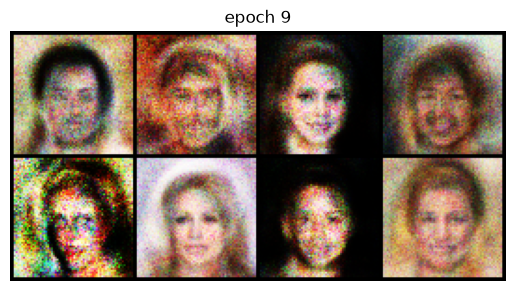

for epoch: 10... batch: 1... G-loss: 1.2972056865692139... D-loss: 0.6349258422851562
for epoch: 10... batch: 51... G-loss: 1.3057290315628052... D-loss: 0.556740403175354
for epoch: 10... batch: 101... G-loss: 1.249643325805664... D-loss: 0.5787851214408875
for epoch: 10... batch: 151... G-loss: 1.2197338342666626... D-loss: 0.5709797143936157
for epoch: 10... batch: 201... G-loss: 1.1154333353042603... D-loss: 0.614033579826355
for epoch: 10... batch: 251... G-loss: 1.3550245761871338... D-loss: 0.5894396305084229
for epoch: 10... batch: 301... G-loss: 1.3347793817520142... D-loss: 0.5238491296768188
for epoch: 10... batch: 351... G-loss: 1.2201365232467651... D-loss: 0.5914571285247803
for epoch: 10... batch: 401... G-loss: 1.3251702785491943... D-loss: 0.595391035079956
for epoch: 10... batch: 451... G-loss: 1.2964215278625488... D-loss: 0.5476810932159424
for epoch: 10... batch: 501... G-loss: 1.1762932538986206... D-loss: 0.5843485593795776
for epoch: 10... batch: 551... G-loss: 

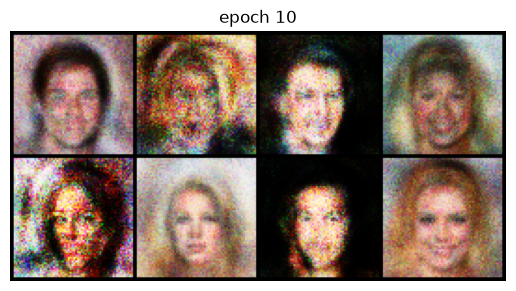

for epoch: 11... batch: 1... G-loss: 1.1208292245864868... D-loss: 0.5761573314666748
for epoch: 11... batch: 51... G-loss: 1.1141860485076904... D-loss: 0.6251432299613953
for epoch: 11... batch: 101... G-loss: 1.205198049545288... D-loss: 0.619959831237793
for epoch: 11... batch: 151... G-loss: 1.187370777130127... D-loss: 0.65925532579422
for epoch: 11... batch: 201... G-loss: 1.1446706056594849... D-loss: 0.6011310815811157
for epoch: 11... batch: 251... G-loss: 1.452069640159607... D-loss: 0.5856250524520874
for epoch: 11... batch: 301... G-loss: 1.140912652015686... D-loss: 0.5961877107620239
for epoch: 11... batch: 351... G-loss: 1.0531119108200073... D-loss: 0.6277309656143188
for epoch: 11... batch: 401... G-loss: 1.2946624755859375... D-loss: 0.5704863667488098
for epoch: 11... batch: 451... G-loss: 1.2347962856292725... D-loss: 0.6146460771560669
for epoch: 11... batch: 501... G-loss: 1.178271770477295... D-loss: 0.5772724151611328
for epoch: 11... batch: 551... G-loss: 1.13

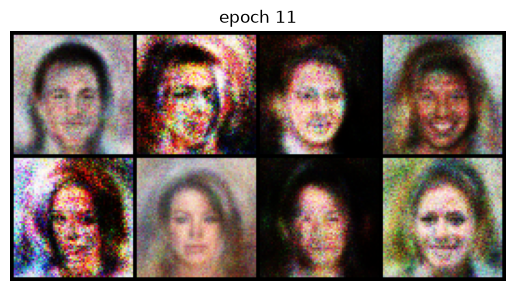

for epoch: 12... batch: 1... G-loss: 1.2190555334091187... D-loss: 0.6036748886108398
for epoch: 12... batch: 51... G-loss: 1.2048664093017578... D-loss: 0.5955789089202881
for epoch: 12... batch: 101... G-loss: 1.1504347324371338... D-loss: 0.6404995918273926
for epoch: 12... batch: 151... G-loss: 1.1665970087051392... D-loss: 0.6792658567428589
for epoch: 12... batch: 201... G-loss: 1.2309538125991821... D-loss: 0.624691367149353
for epoch: 12... batch: 251... G-loss: 1.1240036487579346... D-loss: 0.6695499420166016
for epoch: 12... batch: 301... G-loss: 1.226057529449463... D-loss: 0.5777198076248169
for epoch: 12... batch: 351... G-loss: 1.107611060142517... D-loss: 0.5892736911773682
for epoch: 12... batch: 401... G-loss: 1.288268804550171... D-loss: 0.5790356397628784
for epoch: 12... batch: 451... G-loss: 1.0755643844604492... D-loss: 0.6170895099639893
for epoch: 12... batch: 501... G-loss: 1.1145877838134766... D-loss: 0.6111046075820923
for epoch: 12... batch: 551... G-loss: 

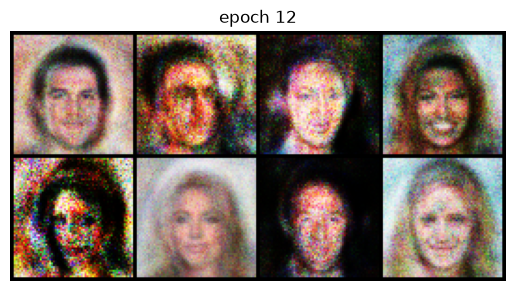

for epoch: 13... batch: 1... G-loss: 1.0868698358535767... D-loss: 0.64990234375
for epoch: 13... batch: 51... G-loss: 1.217117190361023... D-loss: 0.6097231507301331
for epoch: 13... batch: 101... G-loss: 1.1937007904052734... D-loss: 0.603376030921936
for epoch: 13... batch: 151... G-loss: 1.133156657218933... D-loss: 0.5903899073600769
for epoch: 13... batch: 201... G-loss: 1.1132283210754395... D-loss: 0.6150409579277039
for epoch: 13... batch: 251... G-loss: 1.2724888324737549... D-loss: 0.5515958070755005
for epoch: 13... batch: 301... G-loss: 1.1915031671524048... D-loss: 0.6039911508560181
for epoch: 13... batch: 351... G-loss: 1.2881449460983276... D-loss: 0.6605992913246155
for epoch: 13... batch: 401... G-loss: 1.274092197418213... D-loss: 0.5964946746826172
for epoch: 13... batch: 451... G-loss: 1.1589025259017944... D-loss: 0.6286193132400513
for epoch: 13... batch: 501... G-loss: 1.128602385520935... D-loss: 0.5744667053222656
for epoch: 13... batch: 551... G-loss: 1.2108

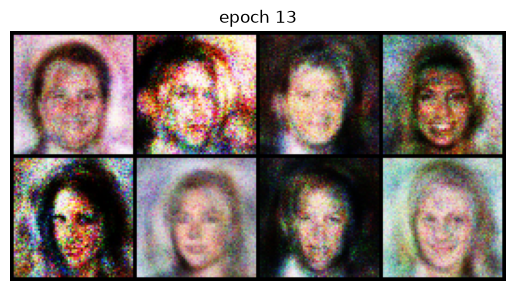

for epoch: 14... batch: 1... G-loss: 0.9922318458557129... D-loss: 0.6188317537307739
for epoch: 14... batch: 51... G-loss: 1.1336644887924194... D-loss: 0.6222332715988159
for epoch: 14... batch: 101... G-loss: 1.1772363185882568... D-loss: 0.6475874185562134
for epoch: 14... batch: 151... G-loss: 1.2051548957824707... D-loss: 0.595943808555603
for epoch: 14... batch: 201... G-loss: 1.1310347318649292... D-loss: 0.6538100242614746
for epoch: 14... batch: 251... G-loss: 1.1562515497207642... D-loss: 0.6096030473709106
for epoch: 14... batch: 301... G-loss: 1.1809016466140747... D-loss: 0.6072951555252075
for epoch: 14... batch: 351... G-loss: 1.1408051252365112... D-loss: 0.5559349060058594
for epoch: 14... batch: 401... G-loss: 1.1491146087646484... D-loss: 0.5331400632858276
for epoch: 14... batch: 451... G-loss: 1.0766079425811768... D-loss: 0.6320666670799255
for epoch: 14... batch: 501... G-loss: 1.0486276149749756... D-loss: 0.639892578125
for epoch: 14... batch: 551... G-loss: 1

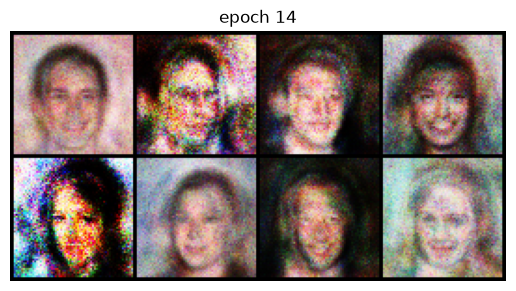

for epoch: 15... batch: 1... G-loss: 1.202722191810608... D-loss: 0.5877745747566223
for epoch: 15... batch: 51... G-loss: 1.1731399297714233... D-loss: 0.6423466801643372
for epoch: 15... batch: 101... G-loss: 1.1855442523956299... D-loss: 0.5682803392410278
for epoch: 15... batch: 151... G-loss: 1.1281330585479736... D-loss: 0.6065305471420288
for epoch: 15... batch: 201... G-loss: 1.1885931491851807... D-loss: 0.5551115274429321
for epoch: 15... batch: 251... G-loss: 1.2126301527023315... D-loss: 0.6402326822280884
for epoch: 15... batch: 301... G-loss: 1.2091031074523926... D-loss: 0.6020305752754211
for epoch: 15... batch: 351... G-loss: 1.18851637840271... D-loss: 0.6219813227653503
for epoch: 15... batch: 401... G-loss: 1.0993738174438477... D-loss: 0.6206201314926147
for epoch: 15... batch: 451... G-loss: 1.1782855987548828... D-loss: 0.5830780267715454
for epoch: 15... batch: 501... G-loss: 1.075894832611084... D-loss: 0.6500898003578186
for epoch: 15... batch: 551... G-loss: 

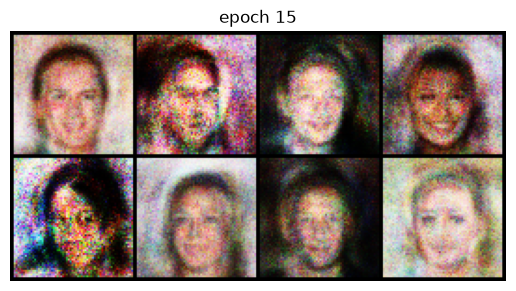

for epoch: 16... batch: 1... G-loss: 1.1357622146606445... D-loss: 0.5672508478164673
for epoch: 16... batch: 51... G-loss: 1.218321681022644... D-loss: 0.5698961019515991
for epoch: 16... batch: 101... G-loss: 1.263047695159912... D-loss: 0.5717008113861084
for epoch: 16... batch: 151... G-loss: 1.116747498512268... D-loss: 0.6464858055114746
for epoch: 16... batch: 201... G-loss: 1.1221461296081543... D-loss: 0.629541277885437
for epoch: 16... batch: 251... G-loss: 1.2521287202835083... D-loss: 0.6345901489257812
for epoch: 16... batch: 301... G-loss: 1.149863600730896... D-loss: 0.6053443551063538
for epoch: 16... batch: 351... G-loss: 1.0555994510650635... D-loss: 0.6471542119979858
for epoch: 16... batch: 401... G-loss: 1.0857317447662354... D-loss: 0.6664420962333679
for epoch: 16... batch: 451... G-loss: 1.1659348011016846... D-loss: 0.5998241901397705
for epoch: 16... batch: 501... G-loss: 1.1919151544570923... D-loss: 0.5934911966323853
for epoch: 16... batch: 551... G-loss: 1

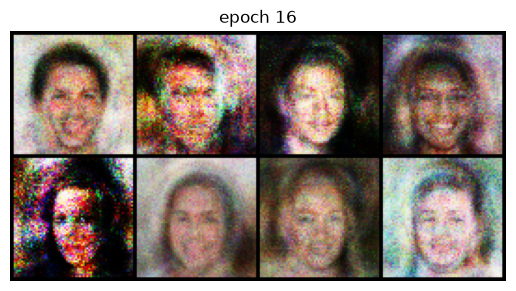

for epoch: 17... batch: 1... G-loss: 1.0939688682556152... D-loss: 0.6202716827392578
for epoch: 17... batch: 51... G-loss: 1.203213095664978... D-loss: 0.5901157855987549
for epoch: 17... batch: 101... G-loss: 1.0614382028579712... D-loss: 0.655353307723999
for epoch: 17... batch: 151... G-loss: 1.1687170267105103... D-loss: 0.590675950050354
for epoch: 17... batch: 201... G-loss: 1.17872154712677... D-loss: 0.6446537375450134
for epoch: 17... batch: 251... G-loss: 1.1058305501937866... D-loss: 0.6160844564437866
for epoch: 17... batch: 301... G-loss: 1.0770797729492188... D-loss: 0.6221181154251099
for epoch: 17... batch: 351... G-loss: 1.089774250984192... D-loss: 0.6290374994277954
for epoch: 17... batch: 401... G-loss: 1.1255736351013184... D-loss: 0.6192967295646667
for epoch: 17... batch: 451... G-loss: 1.2313647270202637... D-loss: 0.5980120897293091
for epoch: 17... batch: 501... G-loss: 1.1036919355392456... D-loss: 0.5924949645996094
for epoch: 17... batch: 551... G-loss: 1.

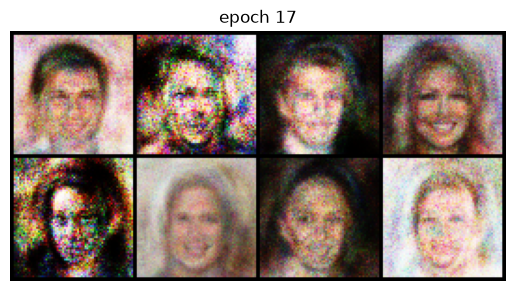

for epoch: 18... batch: 1... G-loss: 1.1187288761138916... D-loss: 0.6328408718109131
for epoch: 18... batch: 51... G-loss: 1.114868402481079... D-loss: 0.6250795125961304
for epoch: 18... batch: 101... G-loss: 1.1954857110977173... D-loss: 0.5949468612670898
for epoch: 18... batch: 151... G-loss: 1.1675395965576172... D-loss: 0.6307429671287537
for epoch: 18... batch: 201... G-loss: 1.0326018333435059... D-loss: 0.637967586517334
for epoch: 18... batch: 251... G-loss: 1.1958179473876953... D-loss: 0.5728107690811157
for epoch: 18... batch: 301... G-loss: 1.162456750869751... D-loss: 0.5687623620033264
for epoch: 18... batch: 351... G-loss: 1.1770832538604736... D-loss: 0.5993680953979492
for epoch: 18... batch: 401... G-loss: 1.1169350147247314... D-loss: 0.6448941230773926
for epoch: 18... batch: 451... G-loss: 1.1140691041946411... D-loss: 0.6431148052215576
for epoch: 18... batch: 501... G-loss: 1.1310980319976807... D-loss: 0.6210849285125732
for epoch: 18... batch: 551... G-loss:

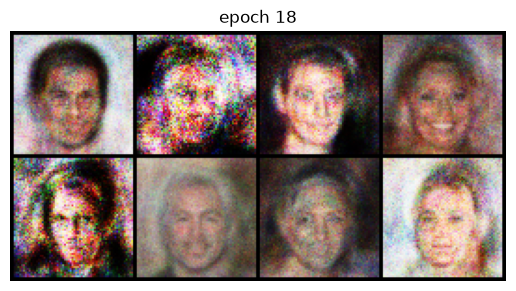

for epoch: 19... batch: 1... G-loss: 1.1138150691986084... D-loss: 0.6012489795684814
for epoch: 19... batch: 51... G-loss: 1.192379117012024... D-loss: 0.579035758972168
for epoch: 19... batch: 101... G-loss: 1.1505154371261597... D-loss: 0.5792449712753296
for epoch: 19... batch: 151... G-loss: 1.070391297340393... D-loss: 0.594842791557312
for epoch: 19... batch: 201... G-loss: 1.1522647142410278... D-loss: 0.587018609046936
for epoch: 19... batch: 251... G-loss: 1.1349858045578003... D-loss: 0.6380940675735474
for epoch: 19... batch: 301... G-loss: 1.0808954238891602... D-loss: 0.6214998364448547
for epoch: 19... batch: 351... G-loss: 1.177019715309143... D-loss: 0.6210637092590332
for epoch: 19... batch: 401... G-loss: 1.1050148010253906... D-loss: 0.5880311727523804
for epoch: 19... batch: 451... G-loss: 1.0119221210479736... D-loss: 0.5978875160217285
for epoch: 19... batch: 501... G-loss: 1.071068286895752... D-loss: 0.6499601602554321
for epoch: 19... batch: 551... G-loss: 1.0

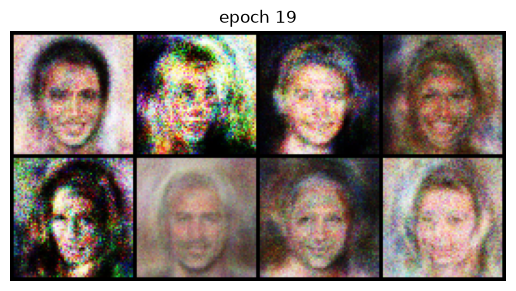

for epoch: 20... batch: 1... G-loss: 1.0302094221115112... D-loss: 0.6664986610412598
for epoch: 20... batch: 51... G-loss: 1.1549696922302246... D-loss: 0.6125922203063965
for epoch: 20... batch: 101... G-loss: 1.134817361831665... D-loss: 0.5888192653656006
for epoch: 20... batch: 151... G-loss: 1.0967830419540405... D-loss: 0.5791182518005371
for epoch: 20... batch: 201... G-loss: 1.1840004920959473... D-loss: 0.570114016532898
for epoch: 20... batch: 251... G-loss: 1.13485848903656... D-loss: 0.6193248629570007
for epoch: 20... batch: 301... G-loss: 1.1410654783248901... D-loss: 0.6248428225517273
for epoch: 20... batch: 351... G-loss: 1.156415581703186... D-loss: 0.6211531162261963
for epoch: 20... batch: 401... G-loss: 1.091391921043396... D-loss: 0.6264263391494751
for epoch: 20... batch: 451... G-loss: 1.0365447998046875... D-loss: 0.6506606340408325
for epoch: 20... batch: 501... G-loss: 1.2669024467468262... D-loss: 0.6381465196609497
for epoch: 20... batch: 551... G-loss: 1.

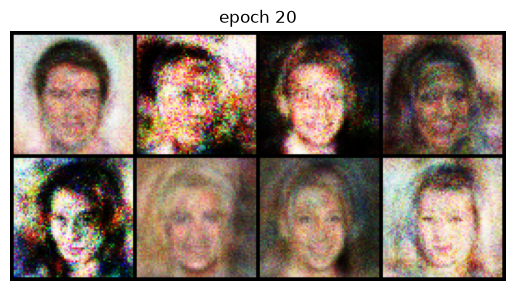

for epoch: 21... batch: 1... G-loss: 1.1882989406585693... D-loss: 0.6053427457809448
for epoch: 21... batch: 51... G-loss: 1.0842229127883911... D-loss: 0.5636962652206421
for epoch: 21... batch: 101... G-loss: 1.225276231765747... D-loss: 0.6447145342826843
for epoch: 21... batch: 151... G-loss: 1.1231151819229126... D-loss: 0.5922789573669434
for epoch: 21... batch: 201... G-loss: 1.0803214311599731... D-loss: 0.5949878692626953
for epoch: 21... batch: 251... G-loss: 1.0766487121582031... D-loss: 0.5692958235740662
for epoch: 21... batch: 301... G-loss: 1.0768026113510132... D-loss: 0.6058384776115417
for epoch: 21... batch: 351... G-loss: 1.1845448017120361... D-loss: 0.6156294345855713
for epoch: 21... batch: 401... G-loss: 1.1243516206741333... D-loss: 0.624229907989502
for epoch: 21... batch: 451... G-loss: 1.1951711177825928... D-loss: 0.6223644018173218
for epoch: 21... batch: 501... G-loss: 1.1144462823867798... D-loss: 0.5824127197265625
for epoch: 21... batch: 551... G-loss

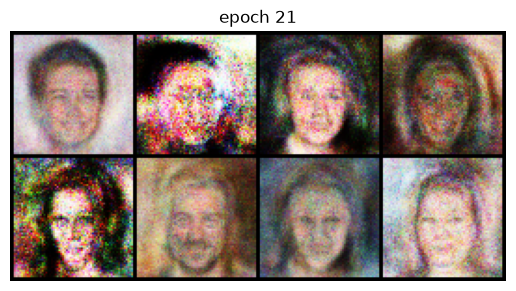

for epoch: 22... batch: 1... G-loss: 1.0518163442611694... D-loss: 0.6278650164604187
for epoch: 22... batch: 51... G-loss: 1.1508044004440308... D-loss: 0.6273342370986938
for epoch: 22... batch: 101... G-loss: 1.041437029838562... D-loss: 0.5948854684829712
for epoch: 22... batch: 151... G-loss: 0.9996731877326965... D-loss: 0.5838257074356079
for epoch: 22... batch: 201... G-loss: 1.0524617433547974... D-loss: 0.5708467960357666
for epoch: 22... batch: 251... G-loss: 1.1614018678665161... D-loss: 0.6092247366905212
for epoch: 22... batch: 301... G-loss: 1.1411664485931396... D-loss: 0.6336307525634766
for epoch: 22... batch: 351... G-loss: 1.1037304401397705... D-loss: 0.6050423383712769
for epoch: 22... batch: 401... G-loss: 1.167582631111145... D-loss: 0.6086181998252869
for epoch: 22... batch: 451... G-loss: 1.21635103225708... D-loss: 0.5432536602020264
for epoch: 22... batch: 501... G-loss: 1.1351505517959595... D-loss: 0.5787592530250549
for epoch: 22... batch: 551... G-loss: 

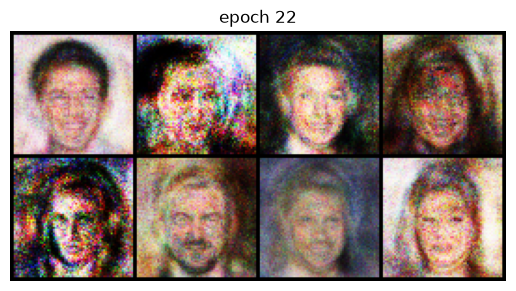

for epoch: 23... batch: 1... G-loss: 1.0171184539794922... D-loss: 0.6341755986213684
for epoch: 23... batch: 51... G-loss: 1.1995210647583008... D-loss: 0.5709807872772217
for epoch: 23... batch: 101... G-loss: 1.096130609512329... D-loss: 0.58754563331604
for epoch: 23... batch: 151... G-loss: 1.1455055475234985... D-loss: 0.5783339738845825
for epoch: 23... batch: 201... G-loss: 1.224095106124878... D-loss: 0.6340535879135132
for epoch: 23... batch: 251... G-loss: 1.1667513847351074... D-loss: 0.6019906997680664
for epoch: 23... batch: 301... G-loss: 1.1868586540222168... D-loss: 0.5983603000640869
for epoch: 23... batch: 351... G-loss: 1.1708509922027588... D-loss: 0.5918622612953186
for epoch: 23... batch: 401... G-loss: 1.2653028964996338... D-loss: 0.5941439867019653
for epoch: 23... batch: 451... G-loss: 1.162123203277588... D-loss: 0.5743629932403564
for epoch: 23... batch: 501... G-loss: 1.1608284711837769... D-loss: 0.5498197078704834
for epoch: 23... batch: 551... G-loss: 1

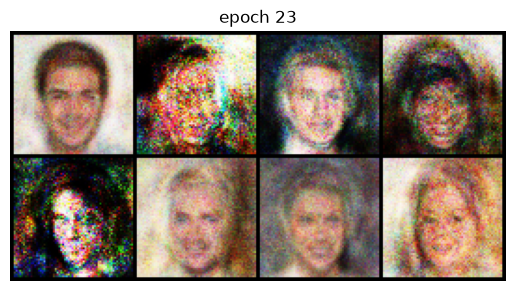

for epoch: 24... batch: 1... G-loss: 1.194923758506775... D-loss: 0.5971026420593262
for epoch: 24... batch: 51... G-loss: 1.1554656028747559... D-loss: 0.5937752723693848
for epoch: 24... batch: 101... G-loss: 1.1084469556808472... D-loss: 0.6231000423431396
for epoch: 24... batch: 151... G-loss: 1.1095666885375977... D-loss: 0.6277726888656616
for epoch: 24... batch: 201... G-loss: 1.2384332418441772... D-loss: 0.5908613801002502
for epoch: 24... batch: 251... G-loss: 1.1457149982452393... D-loss: 0.5379771590232849
for epoch: 24... batch: 301... G-loss: 1.134506106376648... D-loss: 0.6107170581817627
for epoch: 24... batch: 351... G-loss: 1.1399853229522705... D-loss: 0.6021634936332703
for epoch: 24... batch: 401... G-loss: 1.210924506187439... D-loss: 0.6083042621612549
for epoch: 24... batch: 451... G-loss: 1.218976378440857... D-loss: 0.5963214635848999
for epoch: 24... batch: 501... G-loss: 1.17708420753479... D-loss: 0.5779649019241333
for epoch: 24... batch: 551... G-loss: 1.

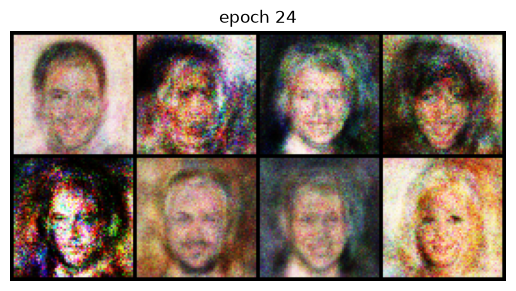

for epoch: 25... batch: 1... G-loss: 1.1219806671142578... D-loss: 0.5471291542053223
for epoch: 25... batch: 51... G-loss: 1.1249690055847168... D-loss: 0.5806300640106201
for epoch: 25... batch: 101... G-loss: 1.173830270767212... D-loss: 0.5916698575019836
for epoch: 25... batch: 151... G-loss: 1.2728477716445923... D-loss: 0.5532976388931274
for epoch: 25... batch: 201... G-loss: 1.1753836870193481... D-loss: 0.6441292762756348
for epoch: 25... batch: 251... G-loss: 1.0807560682296753... D-loss: 0.5847634077072144
for epoch: 25... batch: 301... G-loss: 0.9839116334915161... D-loss: 0.6102789640426636
for epoch: 25... batch: 351... G-loss: 1.091842770576477... D-loss: 0.5850924253463745
for epoch: 25... batch: 401... G-loss: 1.125816822052002... D-loss: 0.6301048398017883
for epoch: 25... batch: 451... G-loss: 1.2482374906539917... D-loss: 0.5854346752166748
for epoch: 25... batch: 501... G-loss: 1.1730809211730957... D-loss: 0.6501462459564209
for epoch: 25... batch: 551... G-loss:

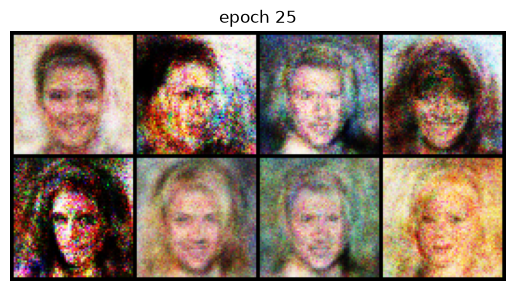

for epoch: 26... batch: 1... G-loss: 1.3279560804367065... D-loss: 0.5940133333206177
for epoch: 26... batch: 51... G-loss: 1.1219562292099... D-loss: 0.5881005525588989
for epoch: 26... batch: 101... G-loss: 1.091766119003296... D-loss: 0.5841272473335266
for epoch: 26... batch: 151... G-loss: 1.208336591720581... D-loss: 0.5976104736328125
for epoch: 26... batch: 201... G-loss: 1.170064926147461... D-loss: 0.5662879943847656
for epoch: 26... batch: 251... G-loss: 1.22816002368927... D-loss: 0.5959919095039368
for epoch: 26... batch: 301... G-loss: 1.1372148990631104... D-loss: 0.5591567754745483
for epoch: 26... batch: 351... G-loss: 1.17996346950531... D-loss: 0.6039305925369263
for epoch: 26... batch: 401... G-loss: 1.152494192123413... D-loss: 0.5791960954666138
for epoch: 26... batch: 451... G-loss: 1.1191331148147583... D-loss: 0.575959324836731
for epoch: 26... batch: 501... G-loss: 1.094961404800415... D-loss: 0.611717164516449
for epoch: 26... batch: 551... G-loss: 1.03806912

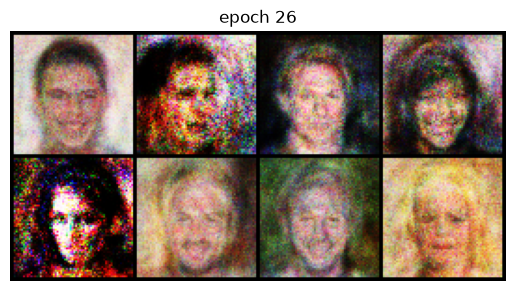

for epoch: 27... batch: 1... G-loss: 1.1786013841629028... D-loss: 0.5956544280052185
for epoch: 27... batch: 51... G-loss: 1.0958681106567383... D-loss: 0.6246412396430969
for epoch: 27... batch: 101... G-loss: 1.2904584407806396... D-loss: 0.5717553496360779
for epoch: 27... batch: 151... G-loss: 1.1672102212905884... D-loss: 0.5986990928649902
for epoch: 27... batch: 201... G-loss: 1.283117651939392... D-loss: 0.5648080110549927
for epoch: 27... batch: 251... G-loss: 1.2388360500335693... D-loss: 0.5899711847305298
for epoch: 27... batch: 301... G-loss: 1.2003040313720703... D-loss: 0.5911135673522949
for epoch: 27... batch: 351... G-loss: 1.17768394947052... D-loss: 0.5921412706375122
for epoch: 27... batch: 401... G-loss: 1.2069084644317627... D-loss: 0.6126422882080078
for epoch: 27... batch: 451... G-loss: 1.161959171295166... D-loss: 0.599804162979126
for epoch: 27... batch: 501... G-loss: 1.1651123762130737... D-loss: 0.5991033911705017
for epoch: 27... batch: 551... G-loss: 1

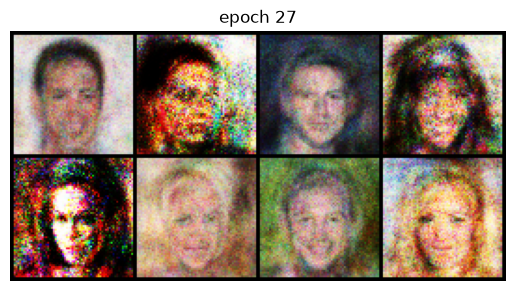

for epoch: 28... batch: 1... G-loss: 1.1899149417877197... D-loss: 0.616538405418396
for epoch: 28... batch: 51... G-loss: 1.2627246379852295... D-loss: 0.5984843969345093
for epoch: 28... batch: 101... G-loss: 1.1339980363845825... D-loss: 0.6010127067565918
for epoch: 28... batch: 151... G-loss: 1.1920499801635742... D-loss: 0.5683597326278687
for epoch: 28... batch: 201... G-loss: 1.3040097951889038... D-loss: 0.5673520565032959
for epoch: 28... batch: 251... G-loss: 1.198461651802063... D-loss: 0.5898569226264954
for epoch: 28... batch: 301... G-loss: 1.0961757898330688... D-loss: 0.6367800235748291
for epoch: 28... batch: 351... G-loss: 1.1628044843673706... D-loss: 0.6164278984069824
for epoch: 28... batch: 401... G-loss: 1.1879395246505737... D-loss: 0.5818319320678711
for epoch: 28... batch: 451... G-loss: 1.2546337842941284... D-loss: 0.5490413904190063
for epoch: 28... batch: 501... G-loss: 1.2081921100616455... D-loss: 0.570197582244873
for epoch: 28... batch: 551... G-loss:

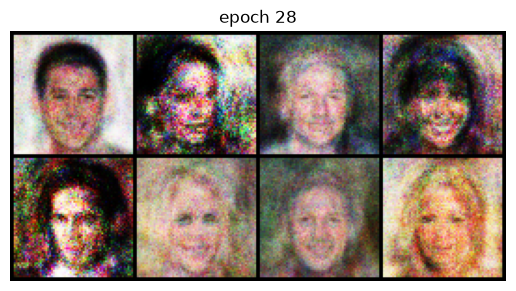

for epoch: 29... batch: 1... G-loss: 1.266141414642334... D-loss: 0.6073397397994995
for epoch: 29... batch: 51... G-loss: 1.2663617134094238... D-loss: 0.5620930790901184
for epoch: 29... batch: 101... G-loss: 1.1986674070358276... D-loss: 0.599297046661377
for epoch: 29... batch: 151... G-loss: 1.168830156326294... D-loss: 0.5693169832229614
for epoch: 29... batch: 201... G-loss: 1.3213173151016235... D-loss: 0.59354168176651
for epoch: 29... batch: 251... G-loss: 1.1493463516235352... D-loss: 0.6224527359008789
for epoch: 29... batch: 301... G-loss: 1.2718145847320557... D-loss: 0.5797768831253052
for epoch: 29... batch: 351... G-loss: 1.217726707458496... D-loss: 0.593629002571106
for epoch: 29... batch: 401... G-loss: 1.1820034980773926... D-loss: 0.59105384349823
for epoch: 29... batch: 451... G-loss: 1.079796314239502... D-loss: 0.6157786250114441
for epoch: 29... batch: 501... G-loss: 1.2117860317230225... D-loss: 0.5907323956489563
for epoch: 29... batch: 551... G-loss: 1.2038

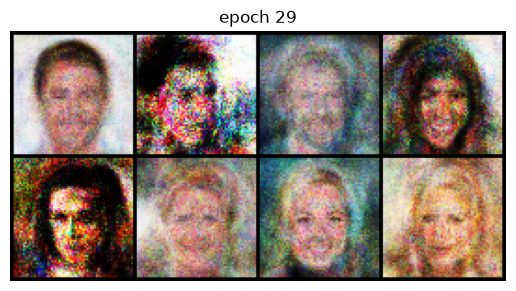

for epoch: 30... batch: 1... G-loss: 1.2413021326065063... D-loss: 0.6224403977394104
for epoch: 30... batch: 51... G-loss: 1.2289113998413086... D-loss: 0.5773310661315918
for epoch: 30... batch: 101... G-loss: 1.2088005542755127... D-loss: 0.5990473031997681
for epoch: 30... batch: 151... G-loss: 1.2586710453033447... D-loss: 0.6017366647720337
for epoch: 30... batch: 201... G-loss: 1.1757774353027344... D-loss: 0.6134198307991028
for epoch: 30... batch: 251... G-loss: 1.1762586832046509... D-loss: 0.5930453538894653
for epoch: 30... batch: 301... G-loss: 1.2950091361999512... D-loss: 0.5656795501708984
for epoch: 30... batch: 351... G-loss: 1.17653226852417... D-loss: 0.6029064059257507
for epoch: 30... batch: 401... G-loss: 1.1568228006362915... D-loss: 0.568906843662262
for epoch: 30... batch: 451... G-loss: 1.117492437362671... D-loss: 0.6358579993247986
for epoch: 30... batch: 501... G-loss: 1.1787761449813843... D-loss: 0.5469099283218384
for epoch: 30... batch: 551... G-loss: 

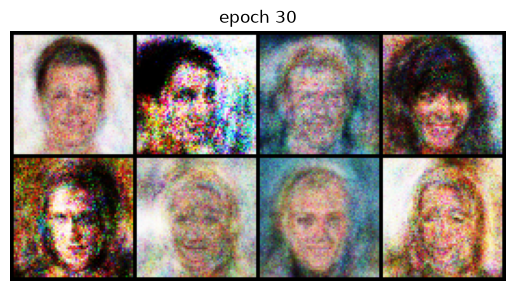

for epoch: 31... batch: 1... G-loss: 1.1563433408737183... D-loss: 0.5792095065116882
for epoch: 31... batch: 51... G-loss: 1.115168809890747... D-loss: 0.5881266593933105


KeyboardInterrupt: 

In [14]:
train(generator, discriminator, dataloader, resume=True)